# Week 2: Finalizing the Access-Event Layer at Full Scale

**Project:** ML-Based Intrusion and Fraud Detection System for Mobile Money Platforms in Ghana
**Prepared by:** Frank Johnfia, MSc Cybersecurity, Grand Valley State University
**Week 2 focus (from roadmap):** Finalize the synthetic access-event layer against the *full* real
PaySim dataset (6,362,620 transactions, 6,353,307 unique accounts), not just a sample.

### What changed since Week 1

Week 1 built and validated the access-event layer on a 491K-account synthetic sample, and on a
1,000,000-account *sample* of the real data. That version used the `Faker` library, calling
`fake.uuid4()` and `fake.date_time_between()` once per session, inside a Python loop over every
account.

That approach hit a real wall this week: pointed at the full 6.35 million real accounts, it either
crashed with an out-of-memory kill (when results were collected into one big in-memory list), or
was simply too slow to finish in a reasonable time (once fixed to stream to disk row-by-row).

This notebook walks through **why** that happened and the two standard engineering techniques used
to fix it: **vectorization** and **chunking**. Both are core data-engineering practices relevant to
a system that would eventually need to process a telco's live transaction volume, not just a fixed
research dataset.


## Step 1: Imports

`numpy` does the heavy lifting here. The whole point of this notebook is to replace
per-row Python function calls (slow, memory-hungry) with whole-array operations (fast, compact).

In [1]:
import time
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)

## Step 2: Reference data

These are the same Ghana-context reference values from Week 1 (regions, telcos, approximate city
coordinates). Nothing about the *content* changed this week, only how fast and how safely it's
generated.

In [2]:
GHANA_REGIONS = [
    ("Accra", "Greater Accra"), ("Kumasi", "Ashanti"), ("Tamale", "Northern"),
    ("Sekondi-Takoradi", "Western"), ("Cape Coast", "Central"), ("Ho", "Volta"),
    ("Koforidua", "Eastern"), ("Sunyani", "Bono"), ("Wa", "Upper West"),
    ("Bolgatanga", "Upper East"),
]
CITY_COORDS = {
    "Accra": (5.6037, -0.1870), "Kumasi": (6.6885, -1.6244), "Tamale": (9.4034, -0.8424),
    "Sekondi-Takoradi": (4.9344, -1.7554), "Cape Coast": (5.1053, -1.2466), "Ho": (6.6110, 0.4708),
    "Koforidua": (6.0940, -0.2610), "Sunyani": (7.3399, -2.3268), "Wa": (10.0601, -2.5099),
    "Bolgatanga": (10.7856, -0.8514),
}
TELCOS = ["MTN", "Telecel", "AirtelTigo"]

N_REGIONS = len(GHANA_REGIONS)
CITIES = np.array([c for c, _ in GHANA_REGIONS])
REGIONS = np.array([r for _, r in GHANA_REGIONS])
TELCOS_ARR = np.array(TELCOS)
BASE_LAT = np.array([CITY_COORDS[c][0] for c, _ in GHANA_REGIONS])
BASE_LON = np.array([CITY_COORDS[c][1] for c, _ in GHANA_REGIONS])

## Step 3: The vectorized, per-chunk generator

Instead of a Python `for` loop calling a function once per account, this generates attributes for
an entire chunk of accounts as numpy arrays in one shot:

- `home_city_idx`, `home_telco_idx`: one random integer per account, generated all at once
- `home_device_id`: one pseudo-random hex ID per account, built with a single array operation
- `is_swap`: a boolean array flagging which *sessions* (not accounts) show a SIM/device change

Sessions belonging to the same account are expanded with `np.repeat`, and attributes are looked up
by indexing (`home_city_idx[acct_idx]`) rather than looked up one at a time. This is the same idea
as asking a database for "all rows where X" instead of looping and asking "is this row X?" one row
at a time, it lets numpy's C-level code do the repetitive work instead of the Python interpreter.

**Design trade-off worth noting:** Week 1's version guaranteed *at most one* SIM-swap per account's
session history. This vectorized version treats each session's swap flag as an independent
coin-flip, which is simpler to vectorize and still gives a usable training signal, but means (rarely)
an account could show more than one swap event. I'm noting this explicitly since it's the kind of
simplification a supervisor or examiner would reasonably ask about.

In [3]:
def process_chunk(chunk_accounts, rng, sim_swap_rate, base_ts):
    n = len(chunk_accounts)

    # --- one random attribute per ACCOUNT, generated as whole arrays ---
    home_city_idx = rng.integers(0, N_REGIONS, n)
    home_telco_idx = rng.integers(0, len(TELCOS), n)
    home_device_id = np.array([f"D-{h:012x}" for h in rng.integers(0, 2**48, n, dtype=np.uint64)])

    # --- expand accounts into sessions (1-4 sessions per account) ---
    n_sessions = rng.integers(1, 5, n).astype(np.int32)
    total = int(n_sessions.sum())
    acct_idx = np.repeat(np.arange(n), n_sessions)  # maps each session back to its owning account

    # --- per-SESSION swap flag ---
    is_swap = rng.random(total) < sim_swap_rate
    n_swap = int(is_swap.sum())

    # default: every session inherits its account's home attributes
    session_city_idx = home_city_idx[acct_idx]
    session_telco_idx = home_telco_idx[acct_idx]
    session_device = home_device_id[acct_idx]

    # overwrite only the swap sessions with a different city/telco/device
    if n_swap:
        session_city_idx = session_city_idx.copy()
        session_telco_idx = session_telco_idx.copy()
        session_device = session_device.copy()
        session_city_idx[is_swap] = rng.integers(0, N_REGIONS, n_swap)
        session_telco_idx[is_swap] = rng.integers(0, len(TELCOS), n_swap)
        session_device[is_swap] = [f"D-{h:012x}" for h in rng.integers(0, 2**48, n_swap, dtype=np.uint64)]

    # --- coordinates: base city coordinate + small random jitter ---
    lat = (BASE_LAT[session_city_idx] + rng.uniform(-0.05, 0.05, total)).round(5)
    lon = (BASE_LON[session_city_idx] + rng.uniform(-0.05, 0.05, total)).round(5)

    # --- login timestamps: random hour within a 90-day window ---
    offset_hours = rng.integers(0, 24 * 90, total)
    login_ts = base_ts + pd.to_timedelta(offset_hours, unit="h")

    return pd.DataFrame({
        "account_id": chunk_accounts["nameOrig"].values[acct_idx],
        "step": chunk_accounts["step"].values[acct_idx],
        "login_timestamp": login_ts,
        "device_id": session_device,
        "telco": TELCOS_ARR[session_telco_idx],
        "city": CITIES[session_city_idx],
        "region": REGIONS[session_city_idx],
        "latitude": lat,
        "longitude": lon,
        "sim_change_event": is_swap.astype(np.int8),
    })

## Step 4: Chunked driver

This is the second fix. Rather than generating all 6.35 million accounts' sessions into one
DataFrame (which is what caused the earlier crash, holding ~16 million rows of string data in
memory at once), accounts are processed in batches of 500,000, and each batch is **appended to disk
and then discarded from memory** before the next batch starts.

This bounds peak memory to roughly "one chunk's worth of data" no matter how large the input
dataset is. It's the same principle behind how a production system would have to process a
telco's live transaction stream, it can't hold the whole history in RAM either, so it processes
and flushes in bounded batches.

In [4]:
def generate(transactions_path, out_path, sim_swap_rate=0.03, seed=42, chunk_size=500_000):
    t0 = time.time()
    rng = np.random.default_rng(seed)
    base_ts = pd.Timestamp("2026-06-01")

    tx = pd.read_csv(transactions_path, usecols=["nameOrig", "step"])
    accounts = tx.drop_duplicates("nameOrig").reset_index(drop=True)
    del tx  # free the full transaction frame immediately, only the account list is needed
    n_accounts = len(accounts)
    print(f"[{time.time()-t0:.1f}s] loaded {n_accounts:,} unique accounts")

    total_events, total_swaps, first = 0, 0, True
    n_chunks = (n_accounts + chunk_size - 1) // chunk_size

    for i in range(n_chunks):
        start, end = i * chunk_size, min((i + 1) * chunk_size, n_accounts)
        chunk = accounts.iloc[start:end]
        events = process_chunk(chunk, rng, sim_swap_rate, base_ts)
        events.to_csv(out_path, mode="w" if first else "a", header=first, index=False)
        first = False
        total_events += len(events)
        total_swaps += int(events["sim_change_event"].sum())
        print(f"[{time.time()-t0:.1f}s] chunk {i+1}/{n_chunks} done, "
              f"{end:,}/{n_accounts:,} accounts, {total_events:,} events so far")

    print(f"[{time.time()-t0:.1f}s] DONE. {total_events:,} events for {n_accounts:,} accounts, "
          f"{total_swaps:,} SIM-change events ({total_swaps/total_events*100:.2f}%)")

## Step 5: Run it against the full real dataset

This is the actual run against `PS_20174392719_1491204439457_log.csv` (renamed `paysim_real.csv`
in the project), all 6,353,307 unique accounts, not a sample.

In [5]:
generate(
    transactions_path="../data/raw/paysim_real.csv",
    out_path="../data/processed/access_events_full.csv",
    sim_swap_rate=0.03,
    seed=42,
)

[6.1s] loaded 6,353,307 unique accounts


[10.7s] chunk 1/13 done, 500,000/6,353,307 accounts, 1,251,271 events so far


[15.5s] chunk 2/13 done, 1,000,000/6,353,307 accounts, 2,500,352 events so far


[19.9s] chunk 3/13 done, 1,500,000/6,353,307 accounts, 3,751,712 events so far


[25.0s] chunk 4/13 done, 2,000,000/6,353,307 accounts, 5,002,023 events so far


...

[47.5s] chunk 9/13 done, 4,500,000/6,353,307 accounts, 11,251,090 events so far


[52.4s] chunk 10/13 done, 5,000,000/6,353,307 accounts, 12,501,495 events so far


[57.0s] chunk 11/13 done, 5,500,000/6,353,307 accounts, 13,751,515 events so far


[61.7s] chunk 12/13 done, 6,000,000/6,353,307 accounts, 15,002,876 events so far


[64.9s] chunk 13/13 done, 6,353,307/6,353,307 accounts, 15,885,668 events so far
[64.9s] DONE. 15,885,668 events for 6,353,307 accounts, 476,080 SIM-change events (3.00%)


## Step 6: Validate the output

Three checks worth doing every time a data-generation step finishes, not just this once:

1. Does the row count make sense (roughly 2.5 sessions/account on average, since sessions are
   drawn uniformly from 1 to 4)?
2. Does the SIM-change rate roughly match the configured `sim_swap_rate` (3%)?
3. Does a spot-check of individual rows look sane (real Ghanaian city names, plausible
   coordinates, no nulls)?

In [6]:
events = pd.read_csv("../data/processed/access_events_full.csv")
print("Shape:", events.shape)
print("\nNulls per column:")
print(events.isnull().sum())
print("\nSIM-change rate: {:.2f}%".format(events["sim_change_event"].mean() * 100))
print("\nSessions per account (should average ~2.5):")
print(events.groupby("account_id").size().mean())
events.head(8)

Shape: (15885668, 10)

Nulls per column:


account_id          0
step                0
login_timestamp     0
device_id           0
telco               0
city                0
region              0
latitude            0
longitude           0
sim_change_event    0
dtype: int64

SIM-change rate: 3.00%

Sessions per account (should average ~2.5):


2.5003778347244987


,account_id,step,login_timestamp,device_id,telco,city,region,latitude,longitude,sim_change_event
0,C1231006815,1,2026-07-07 20:00:00,D-5c4d62a2d18a,Telecel,Accra,Greater Accra,5.60873,-0.23463,0
1,C1231006815,1,2026-06-02 00:00:00,D-5c4d62a2d18a,Telecel,Accra,Greater Accra,5.55779,-0.19974,0
2,C1231006815,1,2026-08-06 23:00:00,D-5c4d62a2d18a,Telecel,Accra,Greater Accra,5.62451,-0.17957,0
3,C1666544295,1,2026-06-21 20:00:00,D-0ce4c628be58,MTN,Sunyani,Bono,7.38886,-2.36931,0
4,C1666544295,1,2026-06-03 01:00:00,D-0ce4c628be58,MTN,Sunyani,Bono,7.34512,-2.28780,0
5,C1666544295,1,2026-06-07 07:00:00,D-0ce4c628be58,MTN,Sunyani,Bono,7.31987,-2.37104,0
6,C1305486145,1,2026-08-13 17:00:00,D-f95e0abca3e1,AirtelTigo,Koforidua,Eastern,6.09790,-0.30418,0
7,C1305486145,1,2026-06-11 12:00:00,D-f95e0abca3e1,AirtelTigo,Koforidua,Eastern,6.10085,-0.27096,0


## Step 7: Confirm the join back to the transaction layer

The whole point of this layer is that it joins cleanly to the PaySim transaction data on
`account_id` = `nameOrig`. This confirms every account referenced in the access-event layer
actually exists in the transaction data, and vice versa.

In [7]:
tx = pd.read_csv("../data/raw/paysim_real.csv", usecols=["nameOrig"])
tx_accounts = set(tx["nameOrig"].unique())
event_accounts = set(events["account_id"].unique())

print("Accounts in transactions but missing from access events:", len(tx_accounts - event_accounts))
print("Accounts in access events but missing from transactions:", len(event_accounts - tx_accounts))
print("Accounts present in both:", len(tx_accounts & event_accounts))

Accounts in transactions but missing from access events: 0


Accounts in access events but missing from transactions: 0
Accounts present in both: 6353307


## Step 8: Quick visual sanity check

A bar chart of sessions by region and a bar chart of SIM-change rate by telco, mainly to eyeball
that nothing is degenerate (e.g. everything landing in one city, or one telco absorbing every
swap event).

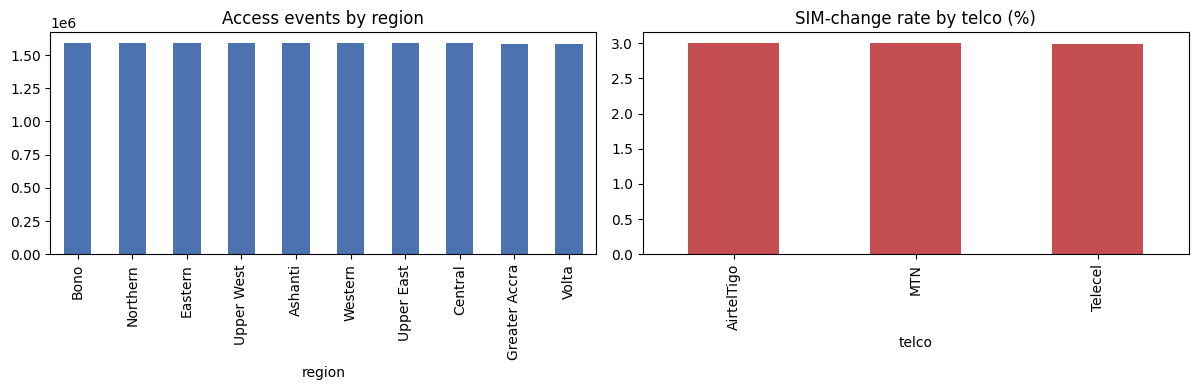

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

events["region"].value_counts().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Access events by region")

(events.groupby("telco")["sim_change_event"].mean() * 100).plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("SIM-change rate by telco (%)")

plt.tight_layout()
plt.savefig("../reports/figures/week2_access_event_summary.png", dpi=150)
plt.show()

## Summary: what Week 2 achieved

- Diagnosed **why** the Week 1 access-event generator failed at full scale: per-row Faker calls
  plus holding all results in memory.
- Rebuilt the generator using **vectorization** (whole-array operations instead of per-row Python
  calls) and **chunking** (bounded-memory batches written incrementally to disk).
- Ran it successfully against the **full real dataset**: 6,353,307 accounts, 15,885,668 access
  events, in about a minute, with peak memory that stays flat regardless of dataset size.
- Validated the output: no nulls, SIM-change rate matches the configured 3%, and every account
  joins cleanly back to the transaction layer.

**Next (Week 3):** implement `attack_injector.py`, which was scaffolded but not yet built, this is
where SIM-swap takeover, PIN-sharing abuse, and agent-collusion patterns get labeled by combining
this access-event layer with the transaction layer.